In [1]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    f1_score, classification_report, balanced_accuracy_score,
    confusion_matrix, matthews_corrcoef, cohen_kappa_score, accuracy_score, precision_score, recall_score
)
from imblearn.over_sampling import SMOTE

In [2]:
with open('/kaggle/input/notebooks/matildeteixeira/wesad-preprocess/processed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X            = data['X']
y            = data['y']
groups       = data['groups']
feature_cols = data['feature_cols']
logo     = LeaveOneGroupOut()
results = []

In [3]:
results = []
for TOP_K in [10, 20, 30, None]:  # None = todas as features (baseline)

    all_true = []
    all_pred = []
    fold_f1s = []

    for train_idx, test_idx in logo.split(X, y, groups):

        X_train = X.iloc[train_idx];  X_test = X.iloc[test_idx]
        y_train = y.iloc[train_idx];  y_test = y.iloc[test_idx]

        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        X_train_proc = imputer.fit_transform(scaler.fit_transform(X_train))
        X_test_proc  = imputer.transform(scaler.transform(X_test))

        if TOP_K is None:
            X_train_sel = X_train_proc
            X_test_sel  = X_test_proc
        else:
            ig_scores = mutual_info_classif(X_train_proc, y_train, random_state=42)
            top_k_idx = np.argsort(ig_scores)[::-1][:TOP_K]
            X_train_sel = X_train_proc[:, top_k_idx]
            X_test_sel  = X_test_proc[:, top_k_idx]

        X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(
            X_train_sel, y_train
        )

        estimators = [
            ('xgb', XGBClassifier(
                n_estimators=200, max_depth=6, learning_rate=0.1,
                n_jobs=-1, random_state=42, eval_metric='mlogloss'
            )),
            ('rf', RandomForestClassifier(
                n_estimators=200, min_samples_split=10, min_samples_leaf=1,
                max_features='sqrt', max_depth=10,
                n_jobs=-1, random_state=42
            )),
            ('lgbm', LGBMClassifier(
                n_estimators=305, max_depth=4, learning_rate=0.195,
                num_leaves=37, min_child_samples=30,
                subsample=0.6537551310524808, colsample_bytree=0.8522263467378263,
                n_jobs=-1, random_state=42, verbose=-1
            )),
        ]

        ensemble = VotingClassifier(estimators=estimators, voting='soft')
        ensemble.fit(X_train_sm, y_train_sm)

        y_pred = ensemble.predict(X_test_sel)
        all_true.extend(y_test)
        all_pred.extend(y_pred)
        fold_f1s.append(f1_score(y_test, y_pred, average='macro', zero_division=0))

    results.append({
        'TOP_K'       : TOP_K if TOP_K is not None else 'All',
        'Macro_F1'    : f1_score(all_true, all_pred, average='macro', zero_division=0),
        'Accuracy'    : accuracy_score(all_true, all_pred),
        'Bal. Acc'    : balanced_accuracy_score(all_true, all_pred),
        'Precision'   : precision_score(all_true, all_pred, average='macro', zero_division=0),
        'Recall'      : recall_score(all_true, all_pred, average='macro', zero_division=0),
        'Std_F1'      : np.std(fold_f1s),
        'Mean_Fold_F1': np.mean(fold_f1s),
    })
    print(f"TOP_K={TOP_K} - Macro F1: {results[-1]['Macro_F1']:.4f} | "
          f"Acc: {results[-1]['Accuracy']:.4f} | Std: {results[-1]['Std_F1']:.4f}")

df_results = pd.DataFrame(results).set_index('TOP_K')
print("\n", df_results.to_string())

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

TOP_K=10 - Macro F1: 0.8085 | Acc: 0.8275 | Std: 0.1434


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

TOP_K=20 - Macro F1: 0.8332 | Acc: 0.8447 | Std: 0.1834


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

TOP_K=30 - Macro F1: 0.8435 | Acc: 0.8545 | Std: 0.1809


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

TOP_K=None - Macro F1: 0.9115 | Acc: 0.9171 | Std: 0.1159

        Macro_F1  Accuracy  Bal. Acc  Precision    Recall    Std_F1  Mean_Fold_F1
TOP_K                                                                           
10     0.808521  0.827542  0.801662   0.818554  0.801662  0.143387      0.789823
20     0.833169  0.844716  0.835843   0.830847  0.835843  0.183413      0.816245
30     0.843462  0.854518  0.845652   0.841499  0.845652  0.180867      0.829131
All    0.911489  0.917111  0.917526   0.906742  0.917526  0.115917      0.909416


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



  TOP_K = todas (baseline)
              precision    recall  f1-score   support

    baseline       0.95      0.92      0.93     17577
      stress       0.86      0.92      0.89      9966

    accuracy                           0.92     27543
   macro avg       0.91      0.92      0.91     27543
weighted avg       0.92      0.92      0.92     27543

Accuracy:              0.917
Balanced Accuracy:     0.918
Macro Precision:       0.907
Macro Recall:          0.918
Macro F1 médio:        0.909 ± 0.116


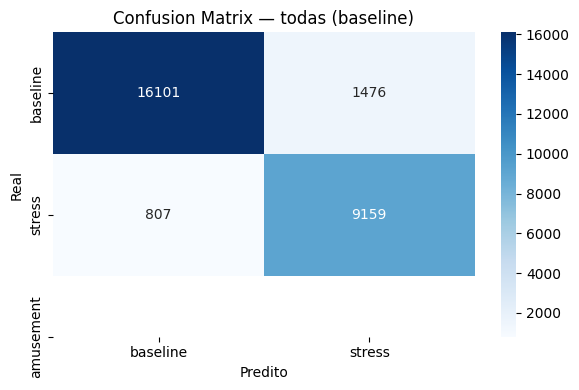

In [4]:
label = "todas (baseline)" if TOP_K is None else f"TOP_{TOP_K}"

print(f"\n{'='*55}")
print(f"  TOP_K = {label}")
print(f"{'='*55}")
print(classification_report(all_true, all_pred,
                            target_names=['baseline', 'stress'],
                            zero_division=0))

macro_f1  = np.mean(fold_f1s)
std_f1    = np.std(fold_f1s)
acc       = accuracy_score(all_true, all_pred)
bal_acc   = balanced_accuracy_score(all_true, all_pred)
precision = precision_score(all_true, all_pred, average='macro', zero_division=0)
recall    = recall_score(all_true, all_pred, average='macro', zero_division=0)

print(f"Accuracy:              {acc:.3f}")
print(f"Balanced Accuracy:     {bal_acc:.3f}")
print(f"Macro Precision:       {precision:.3f}")
print(f"Macro Recall:          {recall:.3f}")
print(f"Macro F1 médio:        {macro_f1:.3f} ± {std_f1:.3f}")

results.append({
    'TOP_K':      label,
    'Accuracy':   acc,
    'Bal. Acc':   bal_acc,
    'Precision':  precision,
    'Recall':     recall,
    'Macro F1':   macro_f1,
    'Std F1':     std_f1,
})

# matriz de confusão por TOP_K
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(all_true, all_pred),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['baseline', 'stress'],
            yticklabels=['baseline', 'stress', 'amusement'])
plt.title(f'Confusion Matrix — {label}')
plt.ylabel('Real'); plt.xlabel('Predito')
plt.tight_layout()
plt.show()

In [5]:
results = [r for r in results if r['TOP_K'] in [10, 20, 30, 'All']]
print("\n\nRESUMO COMPARATIVO")
print("="*75)
df_results = pd.DataFrame(results).set_index('TOP_K')
print(df_results.to_string())



RESUMO COMPARATIVO
       Macro_F1  Accuracy  Bal. Acc  Precision    Recall    Std_F1  Mean_Fold_F1
TOP_K                                                                           
10     0.808521  0.827542  0.801662   0.818554  0.801662  0.143387      0.789823
20     0.833169  0.844716  0.835843   0.830847  0.835843  0.183413      0.816245
30     0.843462  0.854518  0.845652   0.841499  0.845652  0.180867      0.829131
All    0.911489  0.917111  0.917526   0.906742  0.917526  0.115917      0.909416


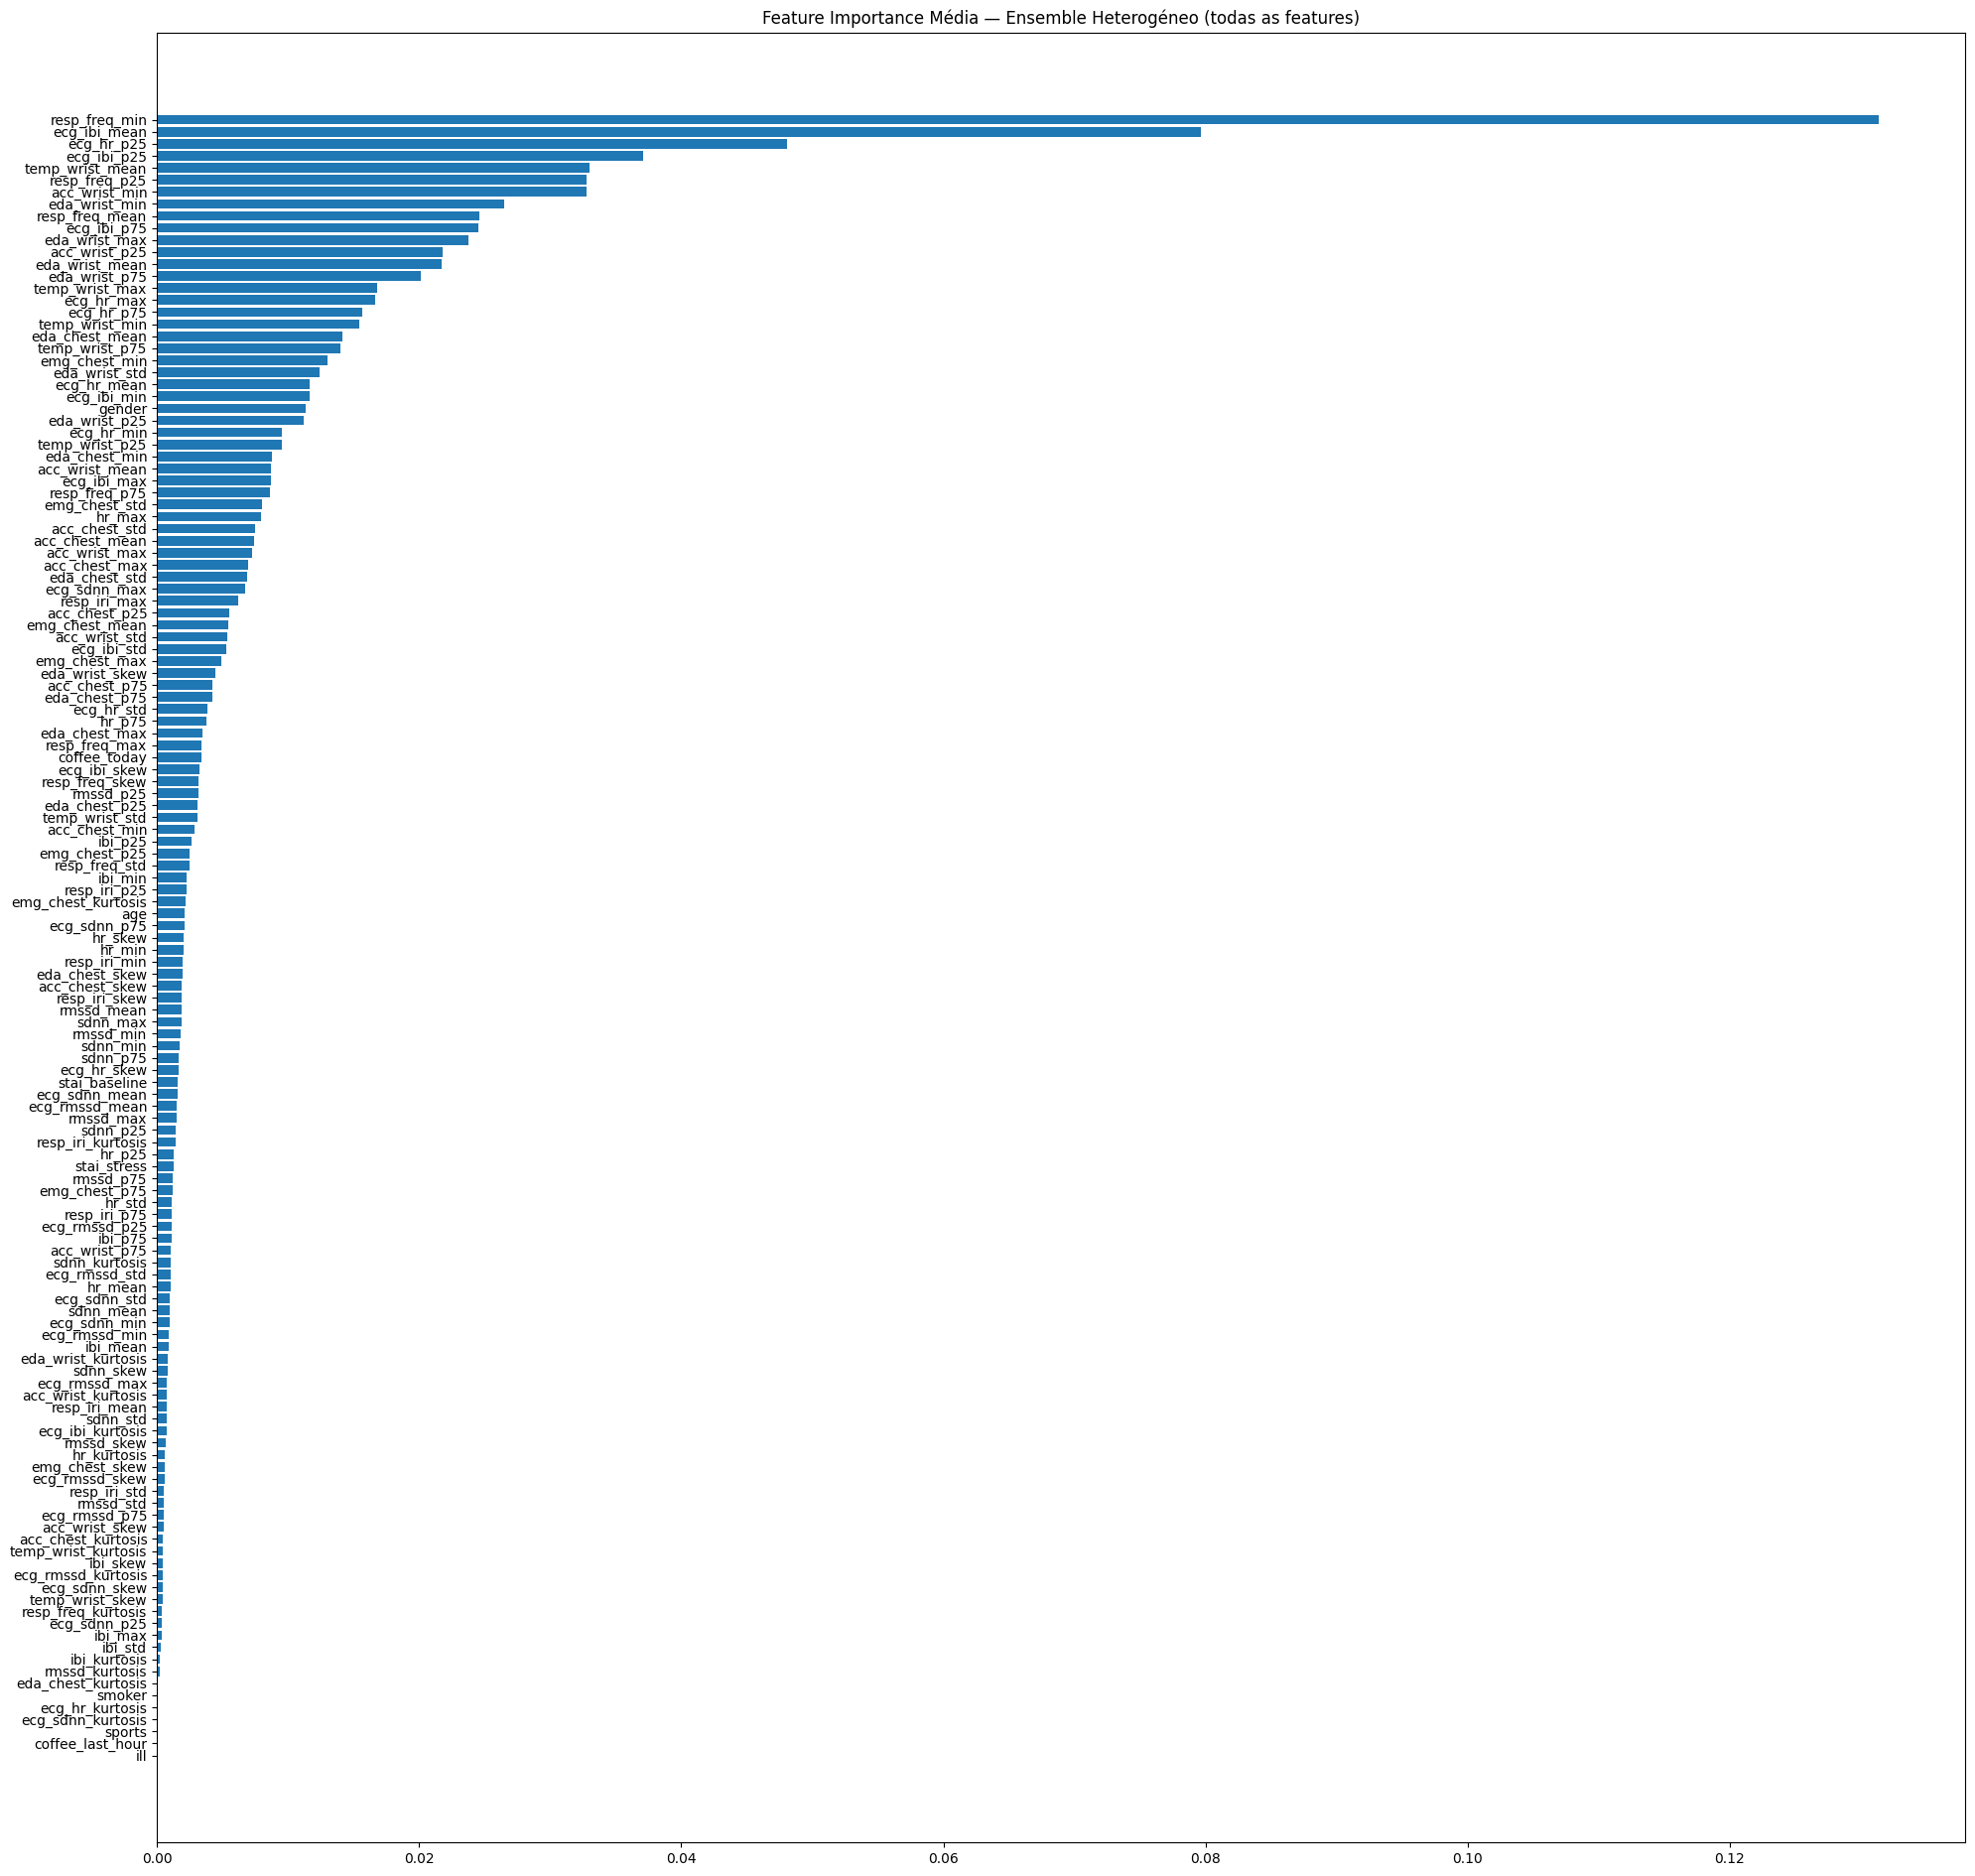

In [6]:
feature_names = np.array(feature_cols)

fi_df = pd.DataFrame({
    'XGB' : ensemble.named_estimators_['xgb'].feature_importances_,
    'RF'  : ensemble.named_estimators_['rf'].feature_importances_,
    'LGBM': ensemble.named_estimators_['lgbm'].feature_importances_,
}, index=feature_names)

# Normaliza por modelo antes de fazer média
fi_df = fi_df / fi_df.sum()
mean_importance = fi_df.mean(axis=1).sort_values()

plt.figure(figsize=(20, 19))
plt.barh(mean_importance.index, mean_importance.values)
plt.title("Feature Importance Média — Ensemble Heterogéneo (todas as features)")
plt.tight_layout()
plt.show()

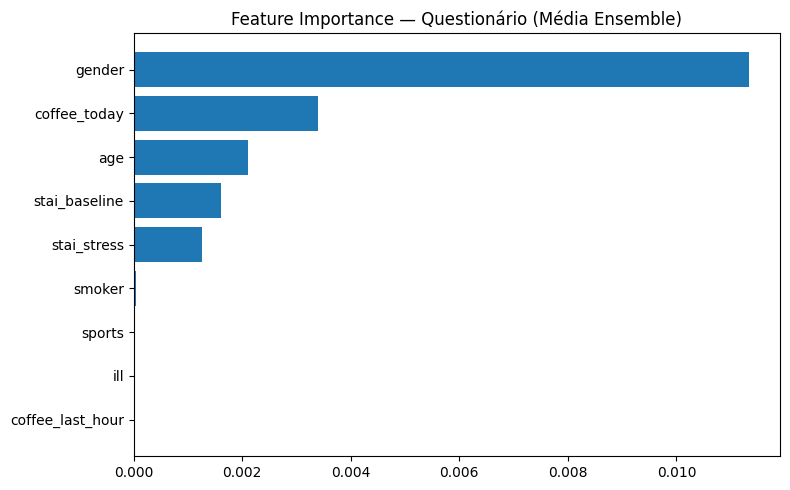

In [7]:
quest_cols = ['age', 'gender', 'coffee_today', 'coffee_last_hour', 'sports', 'smoker', 'ill', 'stai_baseline', 'stai_stress']
quest_indices = [list(feature_cols).index(c) for c in quest_cols]

fi_mean = np.array([
    ensemble.named_estimators_['xgb'].feature_importances_,
    ensemble.named_estimators_['rf'].feature_importances_,
    ensemble.named_estimators_['lgbm'].feature_importances_,
])
fi_mean = (fi_mean / fi_mean.sum(axis=1, keepdims=True)).mean(axis=0)

quest_importances = fi_mean[quest_indices]
indices = np.argsort(quest_importances)

plt.figure(figsize=(8, 5))
plt.barh(np.array(quest_cols)[indices], quest_importances[indices])
plt.title("Feature Importance — Questionário (Média Ensemble)")
plt.tight_layout()
plt.show()

In [8]:
def get_importance(model, name):
    if hasattr(model, 'feature_importances_'):
        return model.feature_importances_
    elif hasattr(model, 'coef_'):
        # LR com l1/l2: coef_ shape (1, n_features) ou (n_classes, n_features)
        return np.abs(model.coef_).mean(axis=0)
    else:
        return None  # SVM poly - sem importância direta

In [9]:
available = {}
for name in ['xgb', 'rf', 'lgbm']:
    imp = get_importance(ensemble.named_estimators_[name], name)
    if imp is not None:
        imp = imp / imp.sum()
        available[name.upper()] = imp
        
for name, col in available.items():
    print(f"{name}: max={col.max():.4f}, std={col.std():.4f}, nonzero={np.sum(col > 0)}/{len(col)}")

XGB: max=0.2854, std=0.0305, nonzero=107/137
RF: max=0.0818, std=0.0136, nonzero=135/137
LGBM: max=0.0509, std=0.0087, nonzero=128/137


## Ensemble with All Models

In [10]:
results = []

for TOP_K in [10, 20, 30, None]:  # None = todas as features (baseline)
    all_true = []
    all_pred = []
    fold_f1s = []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train = X.iloc[train_idx];  X_test = X.iloc[test_idx]
        y_train = y.iloc[train_idx];  y_test = y.iloc[test_idx]

        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        X_train_proc = imputer.fit_transform(scaler.fit_transform(X_train))
        X_test_proc  = imputer.transform(scaler.transform(X_test))

        if TOP_K is None:
            X_train_sel = X_train_proc
            X_test_sel  = X_test_proc
        else:
            ig_scores = mutual_info_classif(X_train_proc, y_train, random_state=42)
            top_k_idx = np.argsort(ig_scores)[::-1][:TOP_K]
            X_train_sel = X_train_proc[:, top_k_idx]
            X_test_sel  = X_test_proc[:, top_k_idx]

        X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(
            X_train_sel, y_train
        )

        estimators = [
            ('xgb', XGBClassifier(
                n_estimators=200, max_depth=6, learning_rate=0.1,
                n_jobs=-1, random_state=42, eval_metric='mlogloss'
            )),
            ('rf', RandomForestClassifier(
                n_estimators=200, min_samples_split=10, min_samples_leaf=1,
                max_features='sqrt', max_depth=10,
                n_jobs=-1, random_state=42
            )),
            ('lgbm', LGBMClassifier(
                n_estimators=305, max_depth=4, learning_rate=0.195,
                num_leaves=37, min_child_samples=30,
                subsample=0.6537551310524808, colsample_bytree=0.8522263467378263,
                n_jobs=-1, random_state=42, verbose=-1
            )),
            ('lr', LogisticRegression(
                C=0.1, max_iter=3000, penalty='l1',
                random_state=42, solver='saga'
            )),
            ('svm', SVC(
                C=0.1, kernel='poly', gamma='auto', degree=3,
                class_weight='balanced', probability=True  
            )),
        ]

        ensemble = VotingClassifier(estimators=estimators, voting='soft')
        ensemble.fit(X_train_sm, y_train_sm)

        y_pred = ensemble.predict(X_test_sel)
        all_true.extend(y_test)
        all_pred.extend(y_pred)
        fold_f1s.append(f1_score(y_test, y_pred, average='macro', zero_division=0))

    results.append({
        'TOP_K'       : TOP_K if TOP_K is not None else 'All',
        'Macro_F1'    : f1_score(all_true, all_pred, average='macro', zero_division=0),
        'Accuracy'    : accuracy_score(all_true, all_pred),
        'Bal. Acc'    : balanced_accuracy_score(all_true, all_pred),
        'Precision'   : precision_score(all_true, all_pred, average='macro', zero_division=0),
        'Recall'      : recall_score(all_true, all_pred, average='macro', zero_division=0),
        'Std_F1'      : np.std(fold_f1s),
        'Mean_Fold_F1': np.mean(fold_f1s),
    })
    print(f"TOP_K={TOP_K} - Macro F1: {results[-1]['Macro_F1']:.4f} | "
          f"Acc: {results[-1]['Accuracy']:.4f} | Std: {results[-1]['Std_F1']:.4f}")

print("\n\nRESUMO COMPARATIVO")
print("="*75)
df_results = pd.DataFrame(results).set_index('TOP_K')
print(df_results.to_string())

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

TOP_K=10 - Macro F1: 0.8154 | Acc: 0.8327 | Std: 0.1431


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

TOP_K=20 - Macro F1: 0.8502 | Acc: 0.8608 | Std: 0.1718


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

TOP_K=30 - Macro F1: 0.8520 | Acc: 0.8620 | Std: 0.1762


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.

TOP_K=None - Macro F1: 0.8870 | Acc: 0.8938 | Std: 0.1730


RESUMO COMPARATIVO
       Macro_F1  Accuracy  Bal. Acc  Precision    Recall    Std_F1  Mean_Fold_F1
TOP_K                                                                           
10     0.815384  0.832662  0.809975   0.822622  0.809975  0.143076      0.797411
20     0.850206  0.860763  0.852500   0.848155  0.852500  0.171769      0.837160
30     0.852050  0.861961  0.855785   0.848940  0.855785  0.176154      0.840282
All    0.887027  0.893766  0.894586   0.881630  0.894586  0.173042      0.874749



  TOP_K = todas (baseline)
              precision    recall  f1-score   support

    baseline       0.94      0.89      0.91     17577
      stress       0.82      0.90      0.86      9966

    accuracy                           0.89     27543
   macro avg       0.88      0.89      0.89     27543
weighted avg       0.90      0.89      0.89     27543

Accuracy:              0.894
Balanced Accuracy:     0.895
Macro Precision:       0.882
Macro Recall:          0.895
Macro F1 médio:        0.875 ± 0.173


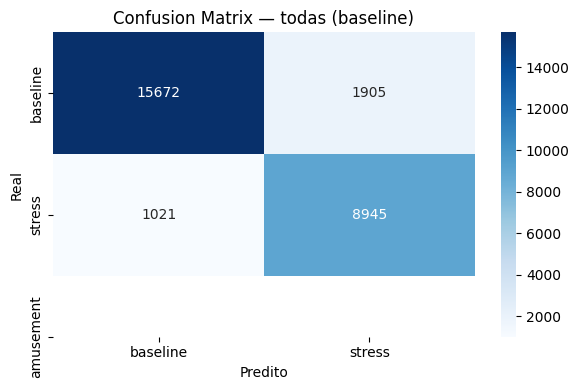

In [11]:
label = "todas (baseline)" if TOP_K is None else f"TOP_{TOP_K}"

print(f"\n{'='*55}")
print(f"  TOP_K = {label}")
print(f"{'='*55}")
print(classification_report(all_true, all_pred,
                            target_names=['baseline', 'stress'],
                            zero_division=0))

macro_f1  = np.mean(fold_f1s)
std_f1    = np.std(fold_f1s)
acc       = accuracy_score(all_true, all_pred)
bal_acc   = balanced_accuracy_score(all_true, all_pred)
precision = precision_score(all_true, all_pred, average='macro', zero_division=0)
recall    = recall_score(all_true, all_pred, average='macro', zero_division=0)

print(f"Accuracy:              {acc:.3f}")
print(f"Balanced Accuracy:     {bal_acc:.3f}")
print(f"Macro Precision:       {precision:.3f}")
print(f"Macro Recall:          {recall:.3f}")
print(f"Macro F1 médio:        {macro_f1:.3f} ± {std_f1:.3f}")

results.append({
    'TOP_K':      label,
    'Accuracy':   acc,
    'Bal. Acc':   bal_acc,
    'Precision':  precision,
    'Recall':     recall,
    'Macro F1':   macro_f1,
    'Std F1':     std_f1,
})

# matriz de confusão por TOP_K
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(all_true, all_pred),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['baseline', 'stress'],
            yticklabels=['baseline', 'stress', 'amusement'])
plt.title(f'Confusion Matrix — {label}')
plt.ylabel('Real'); plt.xlabel('Predito')
plt.tight_layout()
plt.show()


  TOP_K = todas (baseline)
              precision    recall  f1-score   support

    baseline       0.94      0.89      0.91     17577
      stress       0.82      0.90      0.86      9966

    accuracy                           0.89     27543
   macro avg       0.88      0.89      0.89     27543
weighted avg       0.90      0.89      0.89     27543

Accuracy:              0.894
Balanced Accuracy:     0.895
Macro Precision:       0.882
Macro Recall:          0.895
Macro F1 médio:        0.875 ± 0.173


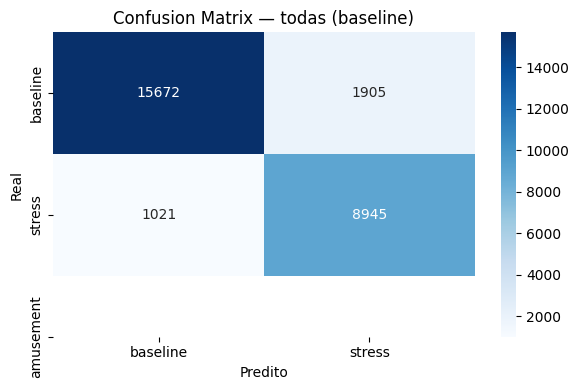

In [12]:
label = "todas (baseline)" if TOP_K is None else f"TOP_{TOP_K}"

print(f"\n{'='*55}")
print(f"  TOP_K = {label}")
print(f"{'='*55}")
print(classification_report(all_true, all_pred,
                            target_names=['baseline', 'stress'],
                            zero_division=0))

macro_f1  = np.mean(fold_f1s)
std_f1    = np.std(fold_f1s)
acc       = accuracy_score(all_true, all_pred)
bal_acc   = balanced_accuracy_score(all_true, all_pred)
precision = precision_score(all_true, all_pred, average='macro', zero_division=0)
recall    = recall_score(all_true, all_pred, average='macro', zero_division=0)

print(f"Accuracy:              {acc:.3f}")
print(f"Balanced Accuracy:     {bal_acc:.3f}")
print(f"Macro Precision:       {precision:.3f}")
print(f"Macro Recall:          {recall:.3f}")
print(f"Macro F1 médio:        {macro_f1:.3f} ± {std_f1:.3f}")

results.append({
    'TOP_K':      label,
    'Accuracy':   acc,
    'Bal. Acc':   bal_acc,
    'Precision':  precision,
    'Recall':     recall,
    'Macro F1':   macro_f1,
    'Std F1':     std_f1,
})

# matriz de confusão por TOP_K
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(all_true, all_pred),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['baseline', 'stress'],
            yticklabels=['baseline', 'stress', 'amusement'])
plt.title(f'Confusion Matrix — {label}')
plt.ylabel('Real'); plt.xlabel('Predito')
plt.tight_layout()
plt.show()

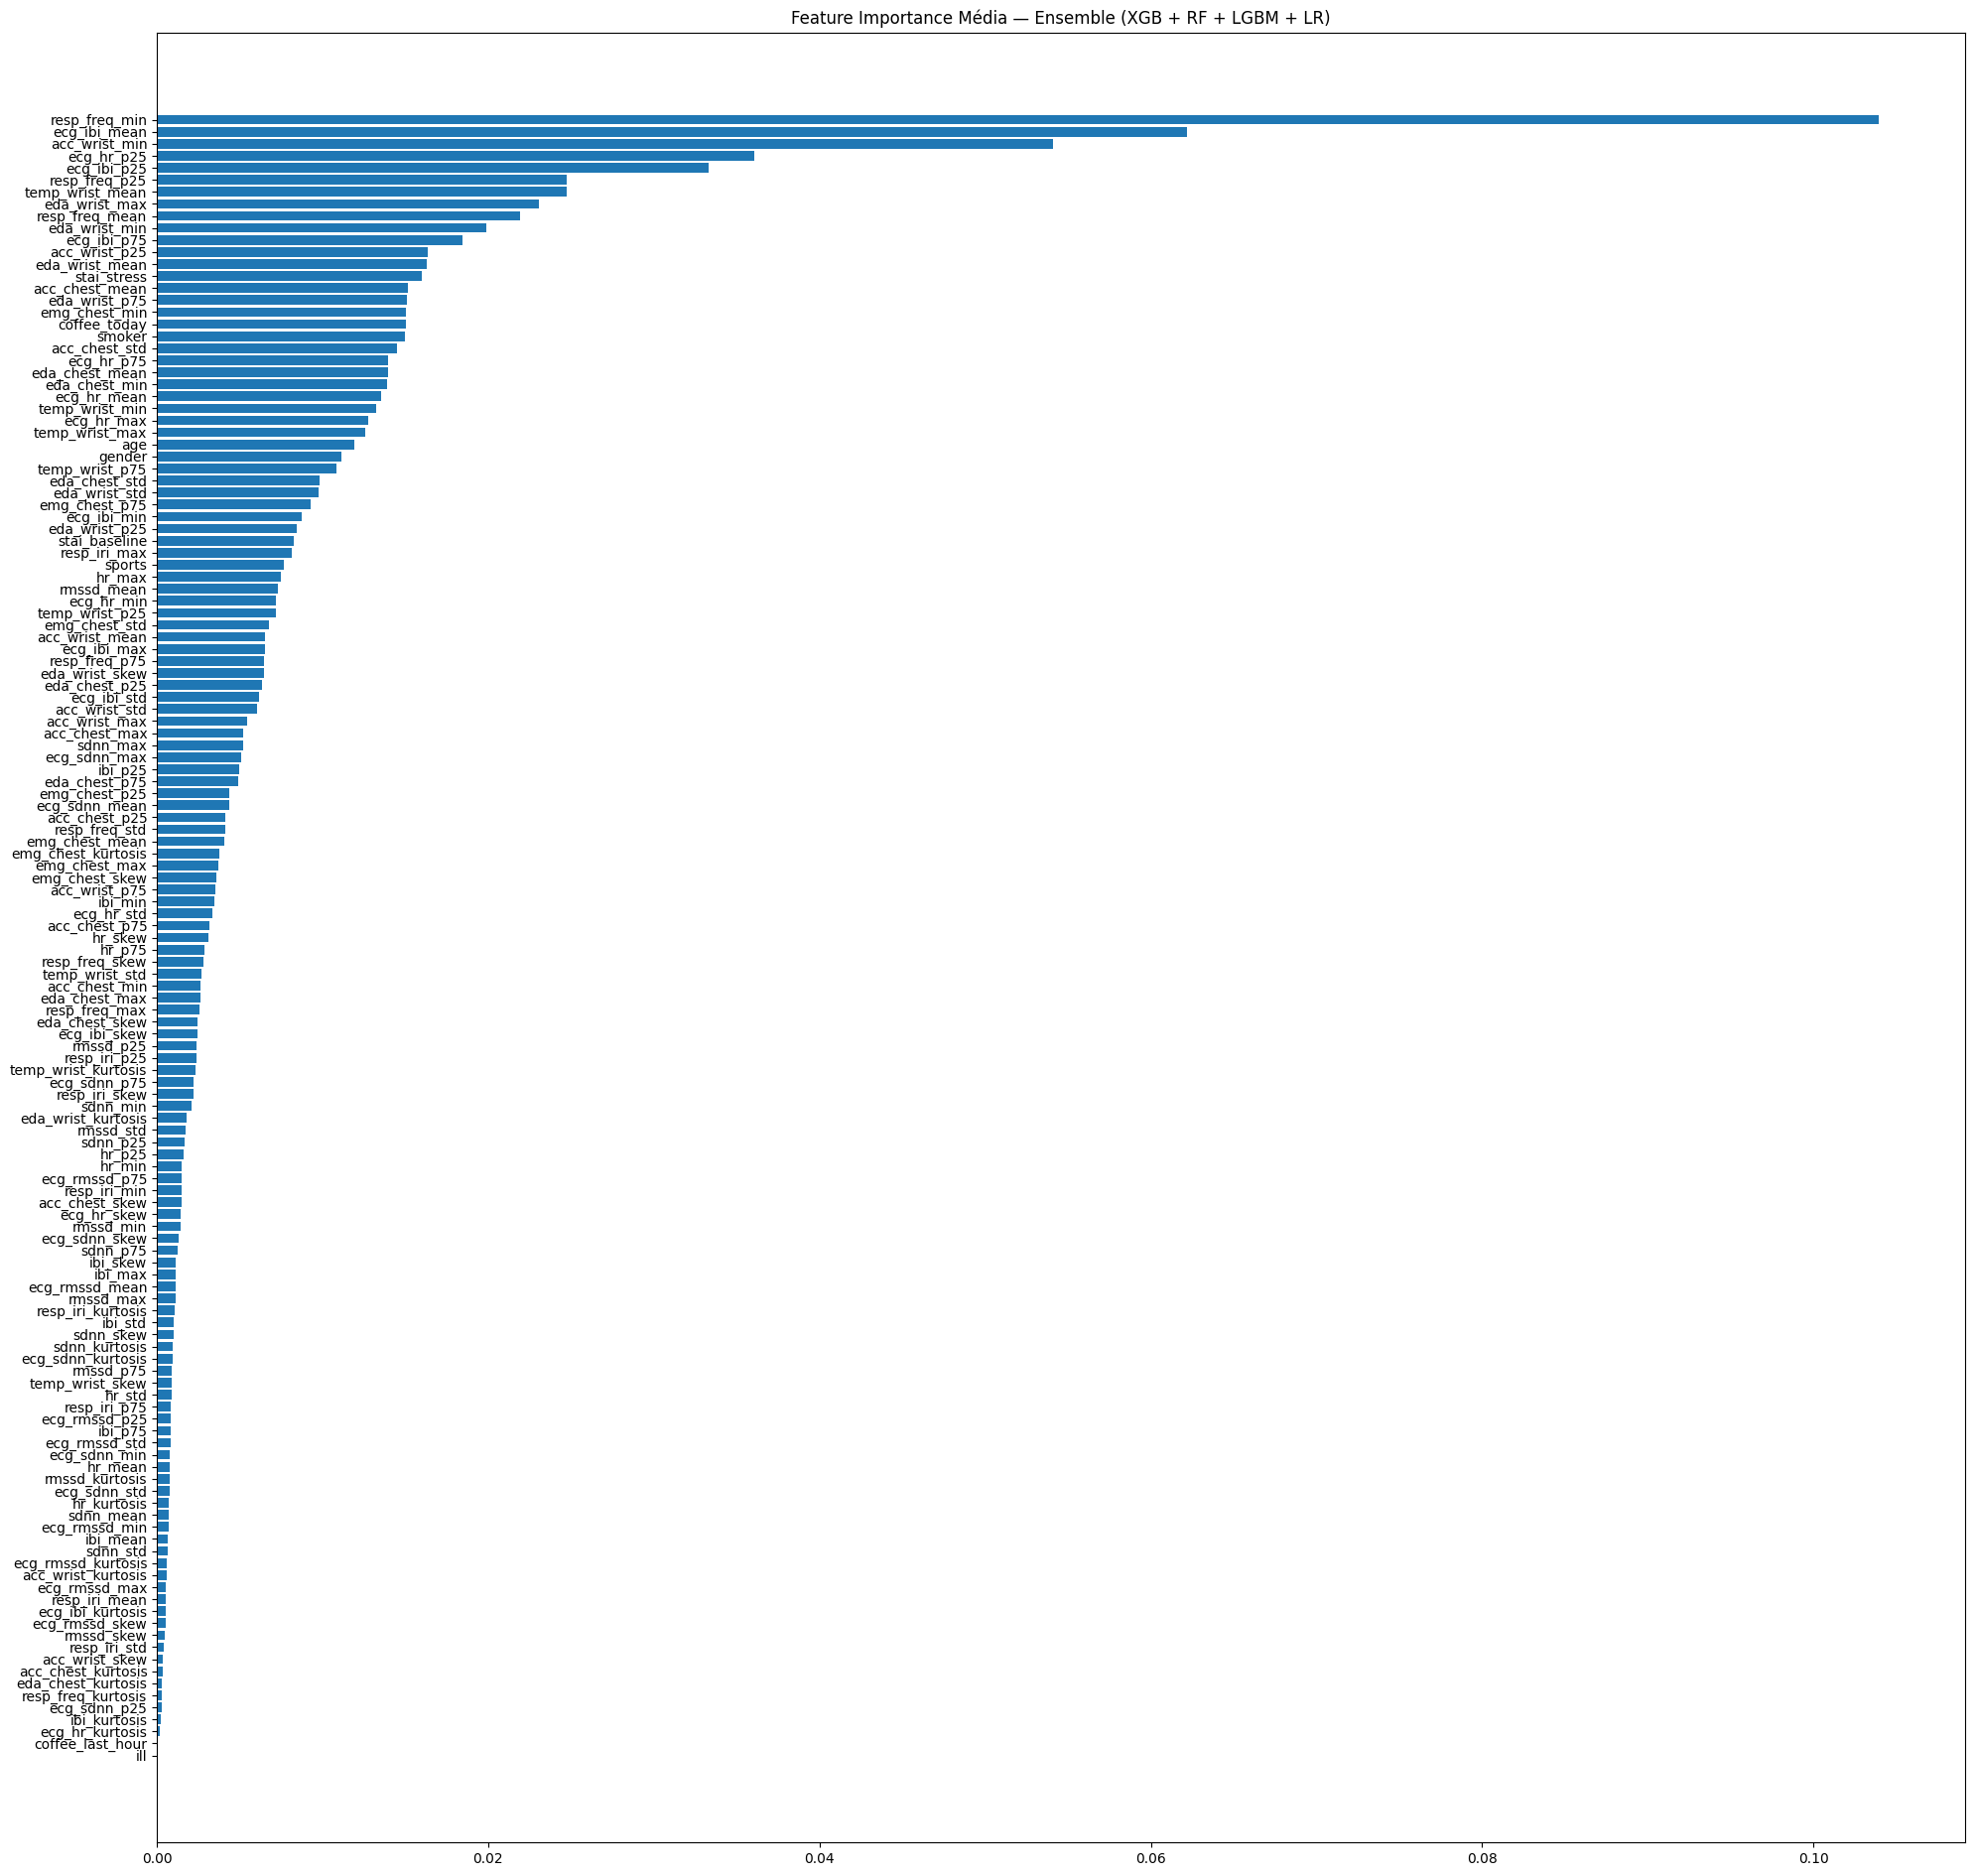

In [13]:
# modelos que têm importância diretas
available = {}
for name in ['xgb', 'rf', 'lgbm', 'lr']:
    imp = get_importance(ensemble.named_estimators_[name], name)
    if imp is not None:
        imp = imp / imp.sum()
        available[name.upper()] = imp

fi_df = pd.DataFrame(available, index=feature_names)
mean_importance = fi_df.mean(axis=1).sort_values()

plt.figure(figsize=(20, 19))
plt.barh(mean_importance.index, mean_importance.values)
plt.title("Feature Importance Média — Ensemble (XGB + RF + LGBM + LR)")
plt.tight_layout()
plt.show()

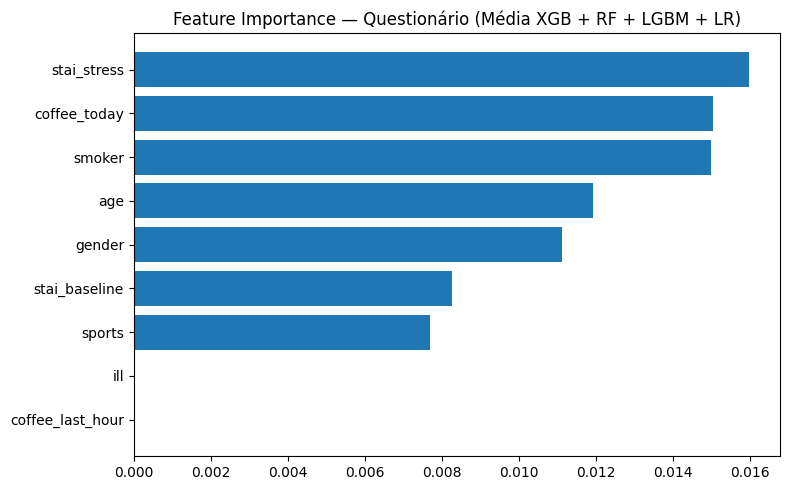

In [14]:
fi_array = np.array([fi_df[m].values for m in fi_df.columns])  # já normalizado
fi_mean_quest = fi_array.mean(axis=0)

quest_cols = ['age', 'gender', 'coffee_today', 'coffee_last_hour',
              'sports', 'smoker', 'ill', 'stai_baseline', 'stai_stress']
quest_indices = [list(feature_cols).index(c) for c in quest_cols]
quest_importances = fi_mean_quest[quest_indices]
indices = np.argsort(quest_importances)

plt.figure(figsize=(8, 5))
plt.barh(np.array(quest_cols)[indices], quest_importances[indices])
plt.title("Feature Importance — Questionário (Média XGB + RF + LGBM + LR)")
plt.tight_layout()
plt.show()

In [15]:
for name, col in available.items():
    print(f"{name}: max={col.max():.4f}, std={col.std():.4f}, nonzero={np.sum(col > 0)}/{len(col)}")

XGB: max=0.2854, std=0.0305, nonzero=107/137
RF: max=0.0818, std=0.0136, nonzero=135/137
LGBM: max=0.0509, std=0.0087, nonzero=128/137
LR: max=0.1179, std=0.0149, nonzero=83/137
